In [1]:
from pathlib import Path
from kedro.framework.startup import bootstrap_project
from kedro.framework.session import KedroSession

project_path = Path.cwd()
if not (project_path / "pyproject.toml").exists():
    project_path = project_path.parent

bootstrap_project(project_path)

session = KedroSession.create(project_path=project_path)
context = session.load_context()
catalog = context.catalog

[11/10/25 00:22:38] INFO     Kedro is sending anonymous usage data with the sole purpose of improving ]8;id=690345;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro_telemetry/plugin.py\plugin.py]8;;\:]8;id=392733;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro_telemetry/plugin.py#243\243]8;;\
                             the product. No personal data or IP addresses are stored on our side. To              
                             opt out, set the `KEDRO_DISABLE_TELEMETRY` or `DO_NOT_TRACK` environment              
                             variables, or create a `.telemetry` file in the current working                       
                             directory with the contents `consent: false`. To hide this message,                   
                             explicitly grant or deny consent. Read more at                                        
                             https://docs.kedro.org/en/stable/configuration/telemetry.html                         

In [2]:
raw = catalog.load("raw_titanic")
raw.head()

[11/10/25 00:25:23] INFO     Loading data from raw_titanic (CSVDataset)...                      ]8;id=464380;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=959467;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py#403\403]8;;\

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
stats = catalog.load("eda_basic_stats")
stats.head()

[11/10/25 00:31:25] INFO     Loading data from eda_basic_stats (CSVDataset)...                  ]8;id=911650;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=612429;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py#403\403]8;;\

,column,count,unique,top,freq,mean,std,min,25%,50%,75%,max,dtype
0,PassengerId,891.0,NaN,NaN,NaN,446.000000,257.353842,1.0,223.5,446.0,668.5,891.0,int64
1,Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0,int64
2,Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0,int64
3,Name,891.0,891.0,"Braund, Mr. Owen Harris",1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,object
4,Sex,891.0,2.0,male,577.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,object


In [5]:
missing = catalog.load("eda_missing_summary")
missing

[11/10/25 00:31:55] INFO     Loading data from eda_missing_summary (CSVDataset)...              ]8;id=740800;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=92265;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py#403\403]8;;\

,column,missing_count,missing_pct
0,Cabin,687,77.10
1,Age,177,19.87
2,Embarked,2,0.22
3,PassengerId,0,0.00
4,Survived,0,0.00
5,Pclass,0,0.00
6,Name,0,0.00
7,Sex,0,0.00
8,SibSp,0,0.00
9,Parch,0,0.00


In [6]:
corr = catalog.load("eda_correlations")
corr

[11/10/25 00:32:08] INFO     Loading data from eda_correlations (CSVDataset)...                 ]8;id=519185;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=182309;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py#403\403]8;;\

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
1,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
2,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
3,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
4,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
5,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
6,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


In [7]:
outliers = catalog.load("eda_outliers_iqr")
outliers

[11/10/25 00:32:21] INFO     Loading data from eda_outliers_iqr (CSVDataset)...                 ]8;id=581696;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=992479;file:///Users/mariiashulyk/Documents/PycharmProjects/ai_project_titanic/.venv/lib/python3.9/site-packages/kedro/io/data_catalog.py#403\403]8;;\

,column,iqr_low,iqr_high,outliers_count
0,Parch,0.0000,0.0000,213
1,Fare,-26.7240,65.6344,116
2,SibSp,-1.5000,2.5000,46
3,Age,-6.6875,64.8125,11
4,PassengerId,-444.0000,1336.0000,0
5,Survived,-1.5000,2.5000,0
6,Pclass,0.5000,4.5000,0


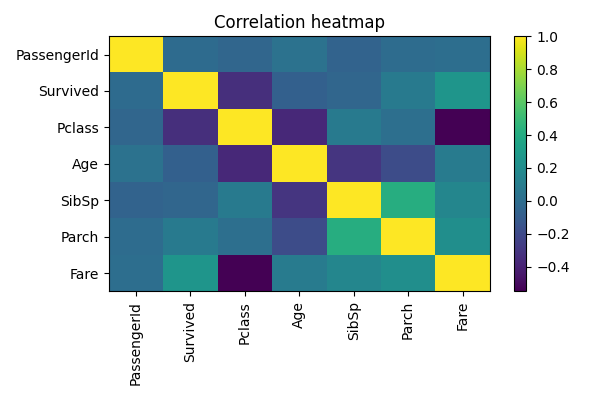

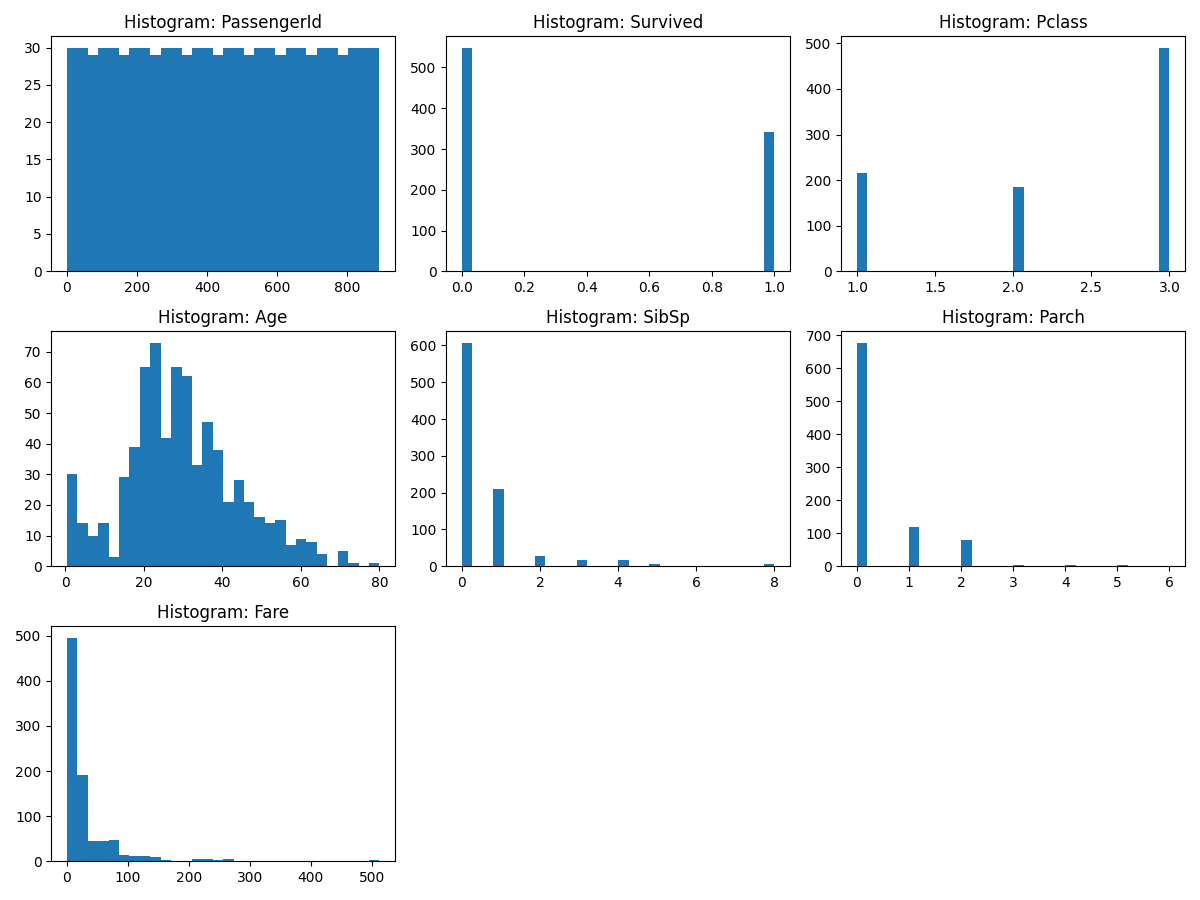

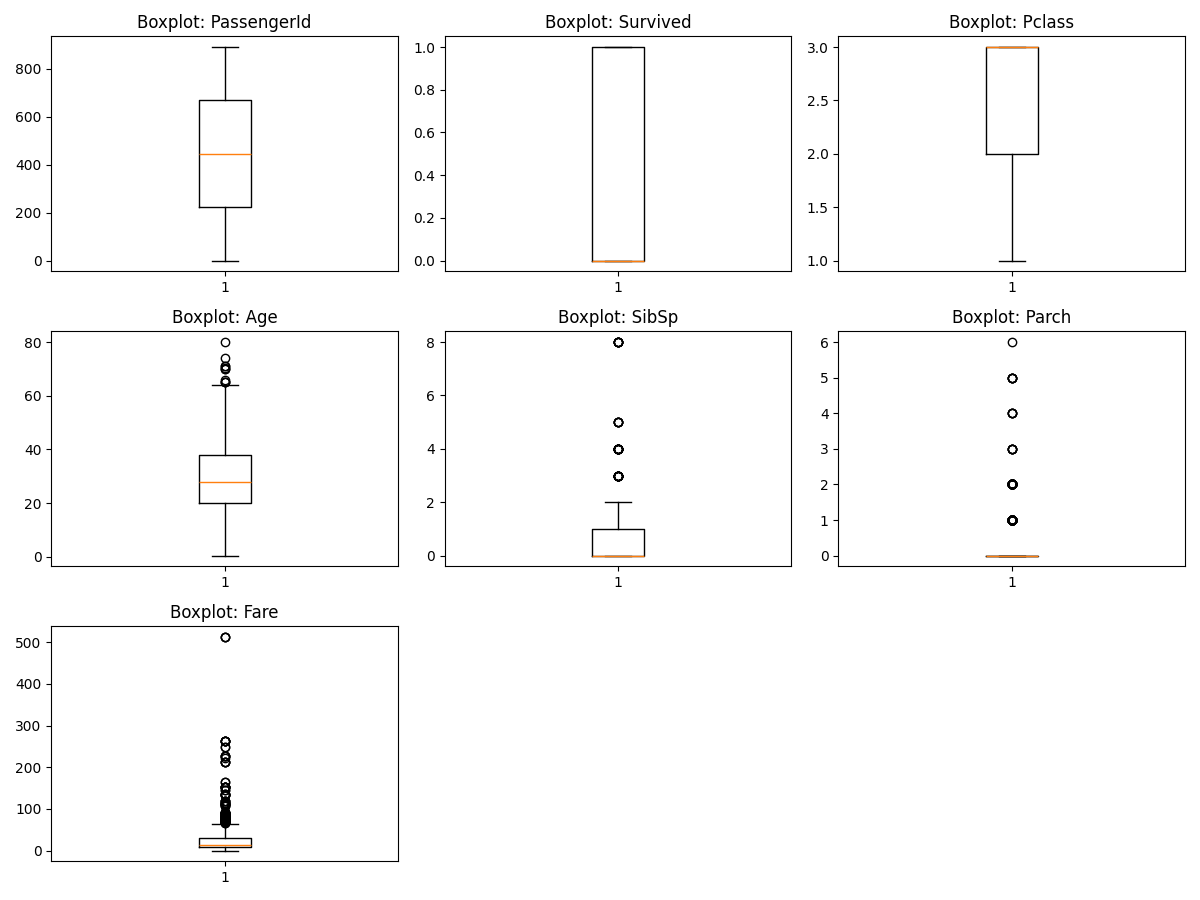

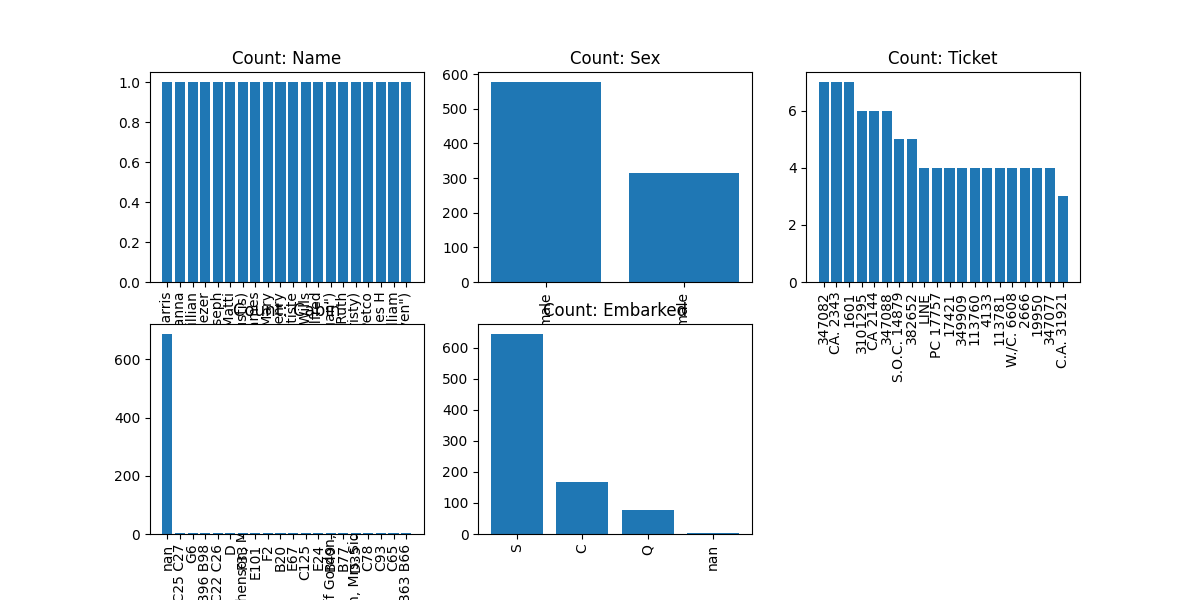

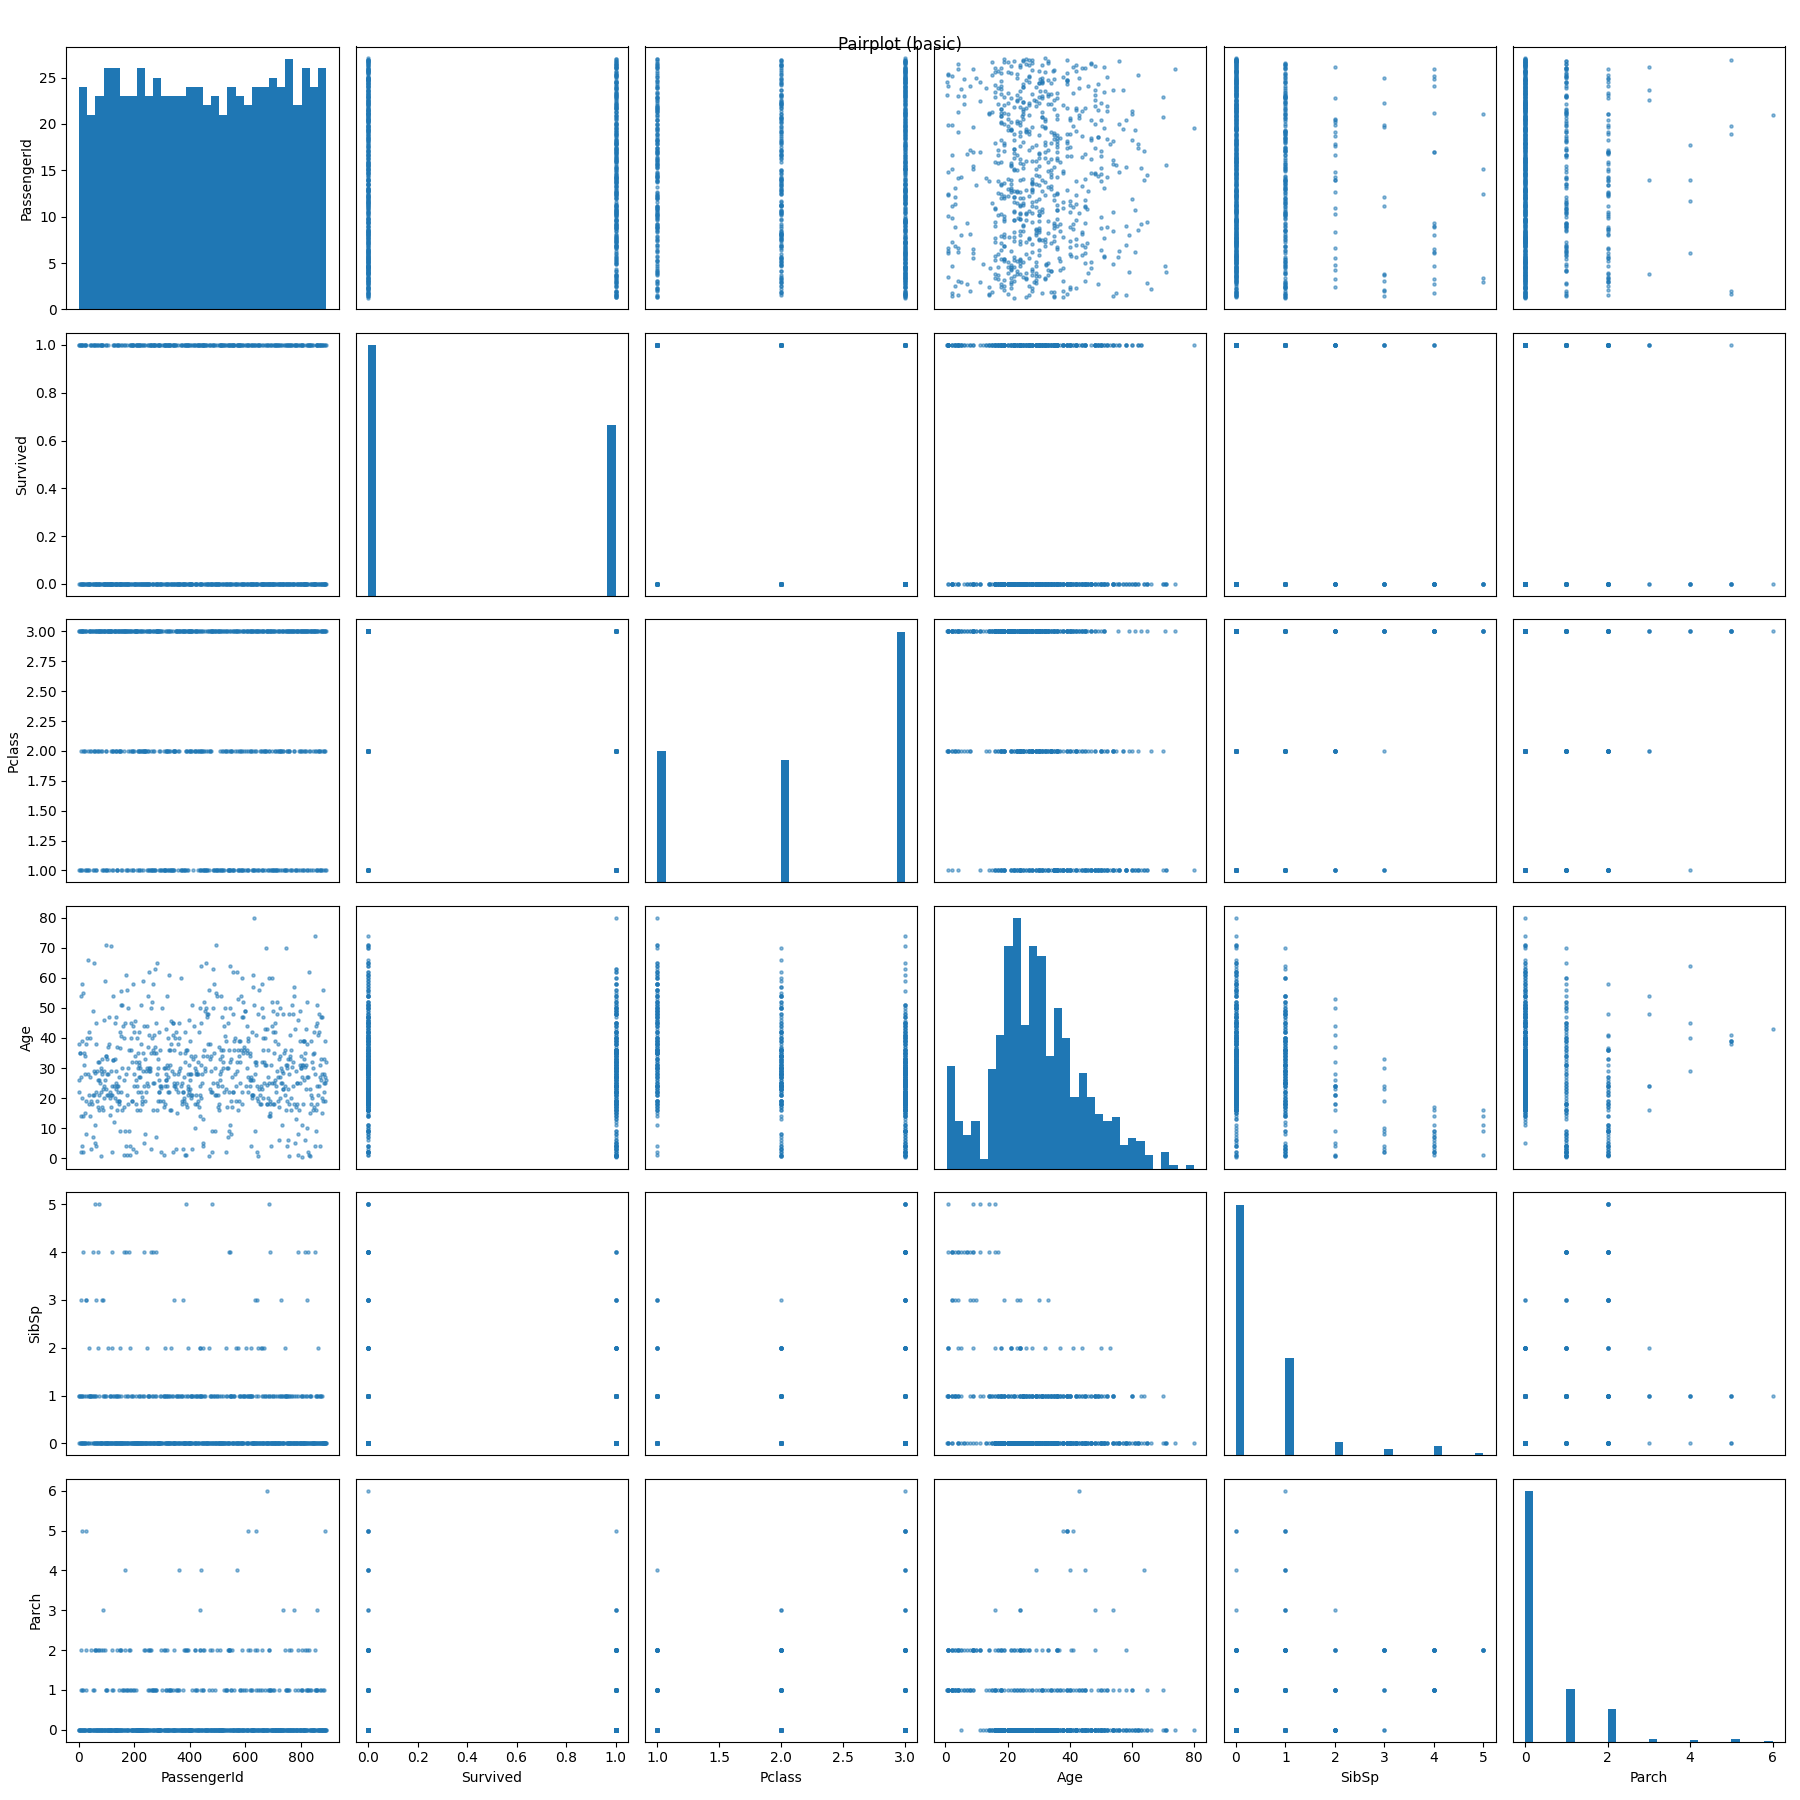

In [8]:
from IPython.display import Image, display
import os

plot_dir = project_path / "docs" / "plots"

for file in os.listdir(plot_dir):
    if file.endswith(".png"):
        display(Image(filename=str(plot_dir / file)))